<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/notebooks/01_nettoyage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd

clients = pd.read_csv("SaintHonore_clients.csv")
boutiques = pd.read_csv("SaintHonore_boutiques.csv")

In [9]:
clients.head()

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_centimes,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m
0,CT80059,BT15,4.0,4.0,1468.0,587200.0,0,0,aucune,en ligne,USA,725.0,oui
1,CT80578,BT28,80.0,3.0,1235.0,370500.0,1,1,argent,boutique,France,1479.0,oui
2,CT80256,BT27,43.0,1.0,1814.0,181400.0,0,2,or,boutique,France,2307.0,oui
3,CT80098,BT16,1.0,1.0,1795.0,179500.0,0,0,or,boutique,Italie,1820.0,non
4,CT80362,BT31,51.0,3.0,2022.0,606600.0,0,0,argent,boutique,Chine,1201.0,oui


In [11]:
clients.shape

(770, 13)

In [13]:
clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 770 entries, 0 to 769
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_id                   770 non-null    object 
 1   boutique_principale         770 non-null    object 
 2   anciennete_mois             770 non-null    float64
 3   nb_achats_12m               770 non-null    float64
 4   panier_moyen_eur            748 non-null    float64
 5   montant_total_centimes      770 non-null    float64
 6   retours                     770 non-null    int64  
 7   demandes_sav                770 non-null    int64  
 8   carte_fidelite              748 non-null    object 
 9   canal_prefere               770 non-null    object 
 10  pays_residence              770 non-null    object 
 11  montant_prochain_achat_eur  770 non-null    float64
 12  est_revenu_6m               770 non-null    object 
dtypes: float64(5), int64(2), object(6)


In [14]:
clients.describe()


,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_centimes,retours,demandes_sav,montant_prochain_achat_eur
count,770.000000,770.000000,748.000000,7.700000e+02,770.000000,770.000000,770.000000
mean,30.848052,3.642857,2615.364973,1.250621e+06,0.484416,0.405195,1975.481818
std,24.332419,2.875118,1876.462418,2.010937e+06,0.768625,0.630375,1126.842693
min,1.000000,0.000000,-200.000000,2.900000e+04,0.000000,0.000000,90.000000
25%,12.000000,2.000000,1512.750000,2.947000e+05,0.000000,0.000000,1267.500000
50%,23.000000,3.000000,2075.000000,5.325000e+05,0.000000,0.000000,1701.500000
75%,49.000000,5.000000,2916.750000,9.285000e+05,1.000000,1.000000,2332.250000
max,116.000000,17.000000,12685.000000,1.141650e+07,5.000000,3.000000,6708.000000


In [15]:
clients.duplicated().sum()


np.int64(70)

In [20]:
clients = clients.drop_duplicates()

In [21]:
clients.shape

(700, 13)

In [22]:
clients.isna().sum()

,0
client_id,0
boutique_principale,0
anciennete_mois,0
nb_achats_12m,0
panier_moyen_eur,21
montant_total_centimes,0
retours,0
demandes_sav,0
carte_fidelite,21
canal_prefere,0


In [23]:
panier_calcule = clients["montant_total_centimes"] / 100 / clients["nb_achats_12m"]
(panier_calcule == clients["panier_moyen_eur"]).sum()

np.int64(673)

In [26]:
clients[clients['nb_achats_12m'] == 0]

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_centimes,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m
35,CT80389,BT14,59.0,0.0,2276.0,455200.0,1,0,NaN,boutique,Italie,1349.0,oui
229,CT80352,BT26,16.0,0.0,1948.0,389600.0,1,1,or,en ligne,France,1311.0,non
603,CT80287,BT17,19.0,0.0,2768.0,553600.0,0,0,aucune,mixte,France,2116.0,non


In [27]:
zero_achat = clients["nb_achats_12m"] == 0

clients.loc[zero_achat, "nb_achats_12m"] = (
    clients.loc[zero_achat, "montant_total_centimes"] / 100
    / clients.loc[zero_achat, "panier_moyen_eur"]
)

clients.loc[zero_achat, ["client_id", "panier_moyen_eur", "montant_total_centimes", "nb_achats_12m"]]

,client_id,panier_moyen_eur,montant_total_centimes,nb_achats_12m
35,CT80389,2276.0,455200.0,2.0
229,CT80352,1948.0,389600.0,2.0
603,CT80287,2768.0,553600.0,2.0


np.int64(676)

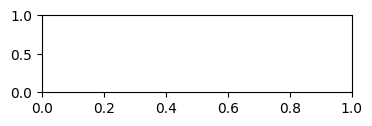

In [28]:
panier_calcule = clients["montant_total_centimes"] / 100 / clients["nb_achats_12m"]
(panier_calcule == clients["panier_moyen_eur"]).sum()

In [29]:
panier_faux = clients["panier_moyen_eur"].isna() | (clients["panier_moyen_eur"] < 0)
panier_faux.sum()

np.int64(24)

In [30]:
clients.loc[panier_faux, "panier_moyen_eur"] = (
    clients.loc[panier_faux, "montant_total_centimes"] / 100
    / clients.loc[panier_faux, "nb_achats_12m"]
)

clients.loc[panier_faux, ["client_id", "nb_achats_12m", "montant_total_centimes", "panier_moyen_eur"]]

,client_id,nb_achats_12m,montant_total_centimes,panier_moyen_eur
21,CT80679,9.0,6350400.0,7056.0
23,CT80013,6.0,1253400.0,2089.0
63,CT80623,1.0,222300.0,2223.0
166,CT80344,3.0,533100.0,1777.0
189,CT80634,6.0,1069200.0,1782.0
205,CT80054,2.0,451600.0,2258.0
312,CT80187,1.0,241400.0,2414.0
324,CT80424,4.0,778800.0,1947.0
344,CT80605,1.0,184000.0,1840.0
365,CT80667,1.0,294100.0,2941.0
